# EDA bốn miền dữ liệu nhân sự

**Đề tài:** Ứng dụng học chuyển giao để dự đoán rủi ro nghỉ việc (TB-HTL)
**Người thực hiện:** Phạm Xuân Thiên (24540028) · **Ngày:** 24/10/2026; cập nhật 25/10/2026 (thêm miền D, mục 6b, 6c)

---

## Mục đích

Notebook này mô tả và so sánh bốn miền dữ liệu dùng trong đề tài, phục vụ mục A2 của báo cáo tiến độ và yêu cầu EDA từng miền trong Bảng 11.

| Miền | Bộ dữ liệu | Nhãn | Loại dữ liệu |
|---|---|---|---|
| A | IBM HR Analytics Employee Attrition | `Attrition` – đã nghỉ việc | Hư cấu |
| B | HR Analytics: Job Change of Data Scientists | `target` – **ý định** đổi việc | Thật (ứng viên khóa đào tạo) |
| C | HR Analytics 14.999 dòng | `left` – đã nghỉ việc | Mô phỏng |
| D | Employee turnover – E. Babushkin | `event` – đã nghỉ việc, **có kiểm duyệt** | Thật |

## Nội dung

1. Số dòng trước và sau khi loại trùng, tỷ lệ dương
2. Tỷ lệ thiếu theo cột
3. Phân phối các biến chính
4. Phân phối khái niệm chung theo từng cặp miền
5. **Chiều tác động** của khái niệm chung với nhãn (Spearman + AUC một đặc trưng)
   - 5b. Khái niệm chung của K2 (L0, L1) sau căn chỉnh C1
   - 5c. Đối chiếu AUC đơn biến với Bảng A5.5a–b
6. Nhận xét

## Nguyên tắc

- Dữ liệu đọc bằng `pairs.LOADERS` để **khớp chính xác** với mã thí nghiệm — cùng cách loại trùng, cùng cách đổi tên cột.
- Thống kê mô tả (số dòng, tỷ lệ thiếu, phân phối đặc trưng) tính trên toàn bộ dữ liệu.
- **Mọi phân tích có liên quan tới nhãn chỉ tính trên phần huấn luyện** của lần chia `rep = 0` (`splits.make_splits`), theo giao thức chống rò rỉ ở mục A4 của báo cáo tiến độ.

## Cách chạy

```bash
cd CN-24540017-MinhTN-ThienPX
# Đặt 4 file CSV vào data/ (xem data/README.md), rồi:
set PYTHONUTF8=1            # Windows; Linux/macOS bỏ qua dòng này
jupyter notebook eda/eda_bon_mien.ipynb
```

## 1. Nạp thư viện và dữ liệu

In [1]:
import json, os, sys, warnings
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.metrics import roc_auc_score

warnings.filterwarnings("ignore")

# Notebook nằm trong eda/ -> thêm thư mục gốc của repo vào sys.path
ROOT = os.path.abspath("..")
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)

from pairs import LOADERS, NAMES, SHORT, PAIRS, concepts
from splits import make_splits

DATA = os.path.join(ROOT, "data")
OUT  = os.path.join(ROOT, "eda", "hinh")
os.makedirs(OUT, exist_ok=True)

FILES = {"A": "WA_Fn-UseC_-HR-Employee-Attrition.csv",
         "B": "aug_train.csv",
         "C": "HR_comma_sep.csv",
         "D": "turnover.csv"}

CO     = [d for d in "ABCD" if os.path.exists(os.path.join(DATA, FILES[d]))]
THIEU  = [d for d in "ABCD" if d not in CO]

print("Miền có dữ liệu :", ", ".join(CO) if CO else "(không có miền nào)")
if THIEU:
    print("Miền còn THIẾU  :", ", ".join(f"{d} (data/{FILES[d]})" for d in THIEU))
    print("\n  -> Notebook vẫn chạy với các miền sẵn có.")
    print("  -> Xem data/README.md để tải và kiểm tra SHA-256 của tệp còn thiếu,")
    print("     rồi chạy lại toàn bộ notebook để có đủ bốn miền.")
if not CO:
    raise FileNotFoundError("Không có tệp dữ liệu nào trong data/ — xem data/README.md.")

Miền có dữ liệu : A, B, C, D


### Bảng màu

Dùng bảng màu đã qua kiểm định độ tương phản và mù màu. Mỗi biểu đồ so sánh **hai miền trong cùng một cặp**, nên chỉ cần hai màu — tránh được vấn đề phân biệt khi có nhiều hơn ba màu cùng lúc.

In [2]:
C1, C2 = "#2a78d6", "#eb6834"          # miền thứ nhất / thứ hai của mỗi cặp
INK, INK2, SURFACE, GRID = "#0b0b0b", "#52514e", "#fcfcfb", "#e4e3df"

mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": GRID,
    "axes.labelcolor": INK2, "text.color": INK, "xtick.color": INK2, "ytick.color": INK2,
    "font.size": 9.5, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110,
})

pd.set_option("display.width", 200, "display.max_columns", 60)

In [3]:
D = {}      # miền -> (X, y, info)
for d in CO:
    X, y, info = LOADERS[d](os.path.join(DATA, FILES[d]))
    D[d] = (X, y, info)
    print(f"{d} — {NAMES[d]}")
    print(f"    {info}")

A — IBM HR (nghỉ việc, hư cấu)
    {'rows_raw': 1470, 'rows': 1470, 'pos': 237}
B — Job Change (ý định đổi việc)
    {'rows_raw': 19158, 'dup_removed': 74, 'conflict_groups': 25, 'rows': 19084, 'pos': 4755}


C — HR Analytics 14.999 (nghỉ việc, mô phỏng)
    {'rows_raw': 14999, 'dup_removed': 3008, 'conflict_groups': 0, 'rows': 11991, 'pos': 1991}
D — Employee turnover – Babushkin (nghỉ việc, dữ liệu thật)
    {'rows_raw': 1129, 'dup_removed': 13, 'conflict_groups': 0, 'person_dup_removed': 163, 'rows': 953, 'pos': 486}


## 2. Số dòng, loại trùng và tỷ lệ dương

Bảng này tái hiện Bảng 12 (mục A2) của báo cáo tiến độ. Việc loại dòng trùng được thực hiện **trước khi chia dữ liệu**, theo giao thức mục 6.4.

In [4]:
rows = []
for d in CO:
    X, y, info = D[d]
    raw = info.get("rows_raw", info["rows"])
    rows.append({
        "Miền": d,
        "Bộ dữ liệu": SHORT[d],
        "Dòng gốc": raw,
        "Trùng đặc trưng": info.get("dup_removed", 0),
        "Trùng cùng người": info.get("person_dup_removed", 0),
        "Nhóm nhãn mâu thuẫn": info.get("conflict_groups", 0),
        "Dòng còn lại": info["rows"],
        "Số cột": X.shape[1],
        "Ca dương": info["pos"],
        "Tỷ lệ dương": round(info["pos"] / info["rows"], 4),
    })
B1 = pd.DataFrame(rows).set_index("Miền")
display(B1)
B1.to_csv(os.path.join(ROOT, "eda", "bang1_tong_quan_mien.csv"), encoding="utf-8-sig")

,Bộ dữ liệu,Dòng gốc,Trùng đặc trưng,Trùng cùng người,Nhóm nhãn mâu thuẫn,Dòng còn lại,Số cột,Ca dương,Tỷ lệ dương
Miền,,,,,,,,,
A,IBM,1470,0,0,0,1470,30,237,0.1612
B,Job Change,19158,74,0,25,19084,11,4755,0.2492
C,HR 14.999,14999,3008,0,0,11991,9,1991,0.1660
D,Babushkin,1129,13,163,0,953,15,486,0.5100


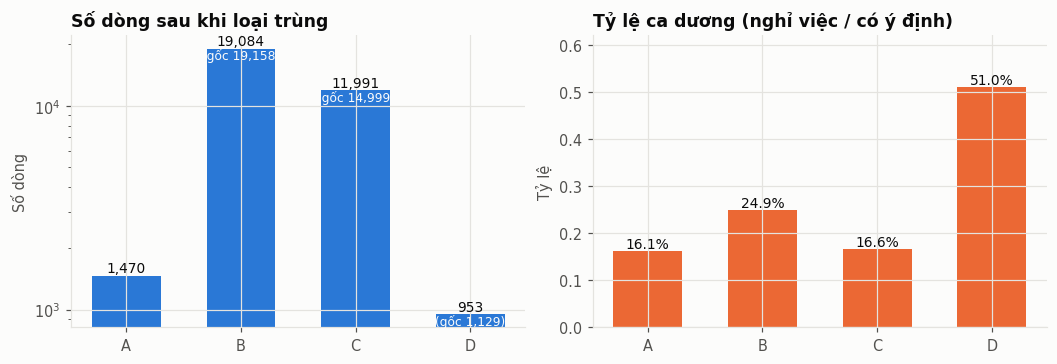

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.2), constrained_layout=True)

ax = axes[0]
ax.bar(B1.index, B1["Dòng còn lại"], color=C1, width=.6)
for i, (v, r) in enumerate(zip(B1["Dòng còn lại"], B1["Dòng gốc"])):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=9, color=INK)
    if r != v:
        ax.text(i, v, f"(gốc {r:,})", ha="center", va="top", fontsize=8, color=SURFACE)
ax.set_title("Số dòng sau khi loại trùng", loc="left", fontweight="bold", color=INK)
ax.set_ylabel("Số dòng"); ax.set_yscale("log")

ax = axes[1]
ax.bar(B1.index, B1["Tỷ lệ dương"], color=C2, width=.6)
for i, v in enumerate(B1["Tỷ lệ dương"]):
    ax.text(i, v, f"{v:.1%}", ha="center", va="bottom", fontsize=9, color=INK)
ax.set_title("Tỷ lệ ca dương (nghỉ việc / có ý định)", loc="left", fontweight="bold", color=INK)
ax.set_ylabel("Tỷ lệ"); ax.set_ylim(0, .62)

plt.savefig(os.path.join(OUT, "h1_dong_va_ty_le_duong.png"), bbox_inches="tight", facecolor=SURFACE)
plt.show()

### Nhận xét mục 2

Số liệu tính lại **khớp chính xác** với Bảng 12 (mục A2) của báo cáo tiến độ 22/10 — xác nhận notebook đọc dữ liệu qua đúng đường mà thí nghiệm dùng.

- **Miền A (IBM, 1.470 dòng):** không có dòng trùng nào. Tỷ lệ nghỉ việc **16,12%** (237 ca). 30 cột sau khi bỏ 4 cột hằng số và cột định danh.
- **Miền B (Job Change, 19.158 → 19.084):** loại **74 dòng trùng đặc trưng**, trong đó có **25 nhóm mà nhãn mâu thuẫn** — cùng một hồ sơ nhưng một bản ghi nhãn 0, bản kia nhãn 1. Tỷ lệ dương **24,92%**, cao nhất trong ba miền.
- **Miền C (HR 14.999 → 11.991):** loại **3.008 dòng trùng hoàn toàn, tức 20,1%**. Đây là tỷ lệ rất cao và là dấu hiệu rõ của dữ liệu mô phỏng. Không có nhóm nào nhãn mâu thuẫn. Tỷ lệ dương **16,60%**, gần bằng miền A.

**Hệ quả cho thí nghiệm:** nếu không loại trùng trước khi chia, 20% số dòng của miền C sẽ xuất hiện ở cả tập huấn luyện lẫn tập kiểm thử. Đây chính là lý do giao thức mục 6.4 bắt buộc loại trùng trước.

- **Miền D (Babushkin, 1.129 → 953):** loại **13 dòng trùng đặc trưng** và **163 bản ghi lặp cùng một người** (trùng mọi cột trừ 5 điểm tính cách). Không có nhóm nhãn mâu thuẫn. Tỷ lệ dương **51,00%** (486 ca) — khác hẳn ba miền trên. `turnover.csv` có SHA-256 khớp `data/README.md` (`50986006…`).

## 3. Tỷ lệ thiếu theo cột

Giá trị thiếu ảnh hưởng trực tiếp tới bước điền khuyết trong `DomainEncoder`, nên cần biết cột nào thiếu và thiếu bao nhiêu.

In [6]:
mi = []
for d in CO:
    X = D[d][0]
    s = X.isna().mean().sort_values(ascending=False)
    s = s[s > 0]
    if len(s) == 0:
        print(f"Miền {d} ({SHORT[d]}): không có giá trị thiếu")
    else:
        print(f"\nMiền {d} ({SHORT[d]}): {len(s)}/{X.shape[1]} cột có giá trị thiếu")
        display(s.to_frame("Tỷ lệ thiếu").style.format("{:.2%}"))
    mi.append(pd.DataFrame({"mien": d, "cot": s.index, "ty_le_thieu": s.values}))

MI = pd.concat(mi, ignore_index=True)
MI.to_csv(os.path.join(ROOT, "eda", "bang2_ty_le_thieu.csv"), index=False, encoding="utf-8-sig")
print(f"\nTổng số cột có giá trị thiếu trên cả 4 miền: {len(MI)}")

Miền A (IBM): không có giá trị thiếu

Miền B (Job Change): 8/11 cột có giá trị thiếu


,Tỷ lệ thiếu
company_type,32.00%
company_size,30.94%
gender,23.62%
major_discipline,14.71%
education_level,2.41%
last_new_job,2.22%
enrolled_university,2.02%
experience,0.34%


Miền C (HR 14.999): không có giá trị thiếu
Miền D (Babushkin): không có giá trị thiếu

Tổng số cột có giá trị thiếu trên cả 4 miền: 8


## 4. Phân phối các biến chính

Với mỗi miền, xem phân phối của một số biến số quan trọng, tách theo nhãn để thấy biến nào có khả năng phân biệt.

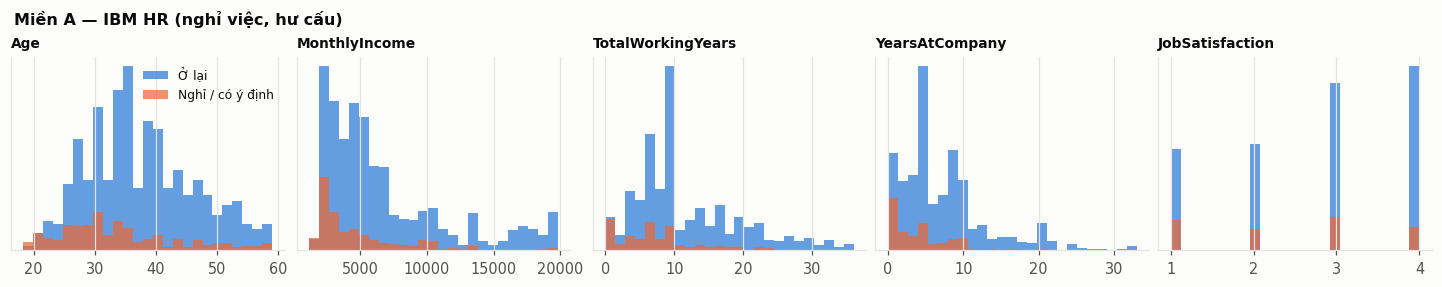

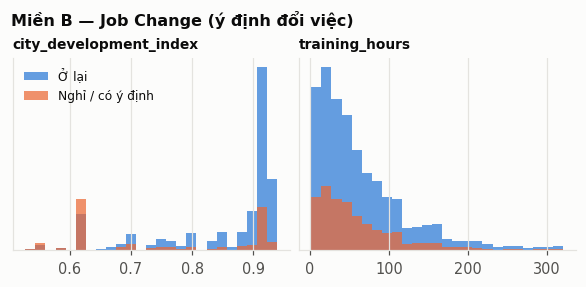

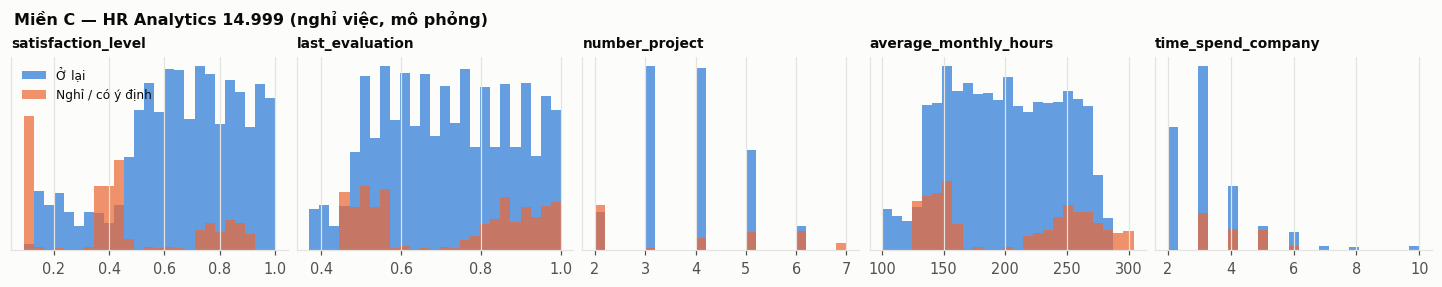

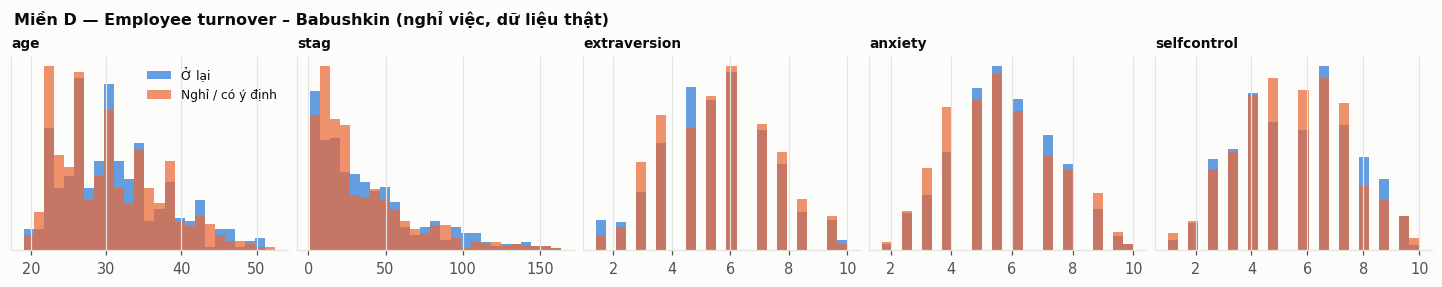

In [7]:
BIEN_CHINH = {
    "A": ["Age", "MonthlyIncome", "TotalWorkingYears", "YearsAtCompany", "JobSatisfaction"],
    "B": ["city_development_index", "training_hours"],
    "C": ["satisfaction_level", "last_evaluation", "number_project",
          "average_monthly_hours", "time_spend_company"],
    "D": ["age", "stag", "extraversion", "anxiety", "selfcontrol"],
}

for d in CO:
    X, y, _ = D[d]
    cols = [c for c in BIEN_CHINH[d] if c in X.columns and pd.api.types.is_numeric_dtype(X[c])]
    if not cols:
        continue
    fig, axes = plt.subplots(1, len(cols), figsize=(2.6 * len(cols), 2.5), constrained_layout=True)
    axes = np.atleast_1d(axes)
    for ax, c in zip(axes, cols):
        v = X[c].astype(float)
        lo, hi = np.nanpercentile(v, [0.5, 99.5])
        bins = np.linspace(lo, hi, 26)
        ax.hist(v[y == 0], bins=bins, color=C1, alpha=.72, label="Ở lại")
        ax.hist(v[y == 1], bins=bins, color=C2, alpha=.72, label="Nghỉ / có ý định")
        ax.set_title(c, loc="left", fontsize=9, fontweight="bold", color=INK)
        ax.set_yticks([])
    axes[0].legend(frameon=False, fontsize=8)
    fig.suptitle(f"Miền {d} — {NAMES[d]}", fontsize=10.5, fontweight="bold",
                 color=INK, x=0.005, ha="left")
    plt.savefig(os.path.join(OUT, f"h2_phan_phoi_{d}.png"), bbox_inches="tight", facecolor=SURFACE)
    plt.show()

## 5. Khái niệm chung theo từng cặp miền

Ba cặp miền của đề tài, lấy trực tiếp từ `pairs.PAIRS` để khớp với thí nghiệm:

| Cặp | Miền | Ngữ nghĩa nhãn | Tập khái niệm chính |
|---|---|---|---|
| AB | IBM ↔ Job Change | **khác** (hành vi ↔ ý định) | `canon4` |
| AC | IBM ↔ HR 14.999 | giống (hành vi ↔ hành vi) | `core` |
| AD | IBM ↔ Babushkin | giống (hành vi ↔ hành vi) | `core` |

In [8]:
for p, cfg in {k: v for k, v in PAIRS.items() if set(v["domains"]) <= set(CO)}.items():
    d1, d2 = cfg["domains"]
    K1 = concepts(p, d1, D[d1][0], cfg["main"])
    K2 = concepts(p, d2, D[d2][0], cfg["main"])
    print(f"\n{'='*72}\nCặp {p}: {SHORT[d1]} ↔ {SHORT[d2]} — ngữ nghĩa nhãn {cfg['label_semantics']}")
    print(f"Tập khái niệm chính '{cfg['main']}': {list(K1.columns)}")
    tk = pd.concat([K1.describe().T.add_prefix(f"{d1}_"),
                    K2.describe().T.add_prefix(f"{d2}_")], axis=1)
    display(tk[[f"{d1}_mean", f"{d1}_std", f"{d1}_min", f"{d1}_max",
                f"{d2}_mean", f"{d2}_std", f"{d2}_min", f"{d2}_max"]].round(3))


Cặp AB: IBM ↔ Job Change — ngữ nghĩa nhãn khác (hành vi ↔ ý định)
Tập khái niệm chính 'canon4': ['male', 'gender_other_missing', 'education', 'experience', 'training']


,A_mean,A_std,A_min,A_max,B_mean,B_std,B_min,B_max
male,0.600,0.490,0.0,1.0,0.689,0.463,0.0,1.0
gender_other_missing,0.000,0.000,0.0,0.0,0.246,0.431,0.0,1.0
education,2.913,1.024,1.0,5.0,3.013,0.950,0.0,5.0
experience,10.520,6.150,0.0,21.0,10.079,6.765,0.0,21.0
training,2.799,1.289,0.0,6.0,65.465,60.115,1.0,336.0



Cặp AC: IBM ↔ HR 14.999 — ngữ nghĩa nhãn giống (hành vi ↔ hành vi)
Tập khái niệm chính 'core': ['satisfaction', 'evaluation', 'tenure', 'promoted_5y', 'pay']


,A_mean,A_std,A_min,A_max,C_mean,C_std,C_min,C_max
satisfaction,2.729,1.103,1.0,4.0,0.630,0.241,0.09,1.0
evaluation,3.154,0.361,3.0,4.0,0.717,0.168,0.36,1.0
tenure,7.008,6.127,0.0,40.0,3.365,1.330,2.00,10.0
promoted_5y,0.854,0.353,0.0,1.0,0.017,0.129,0.00,1.0
pay,6502.931,4707.957,1009.0,19999.0,0.604,0.636,0.00,2.0



Cặp AD: IBM ↔ Babushkin — ngữ nghĩa nhãn giống (hành vi ↔ hành vi)
Tập khái niệm chính 'core': ['male', 'age', 'tenure']


,A_mean,A_std,A_min,A_max,D_mean,D_std,D_min,D_max
male,0.600,0.490,0.0,1.0,0.261,0.440,0.000,1.000
age,36.924,9.135,18.0,60.0,30.898,6.992,18.000,58.000
tenure,6.359,4.442,0.0,15.0,3.105,2.875,0.033,14.954


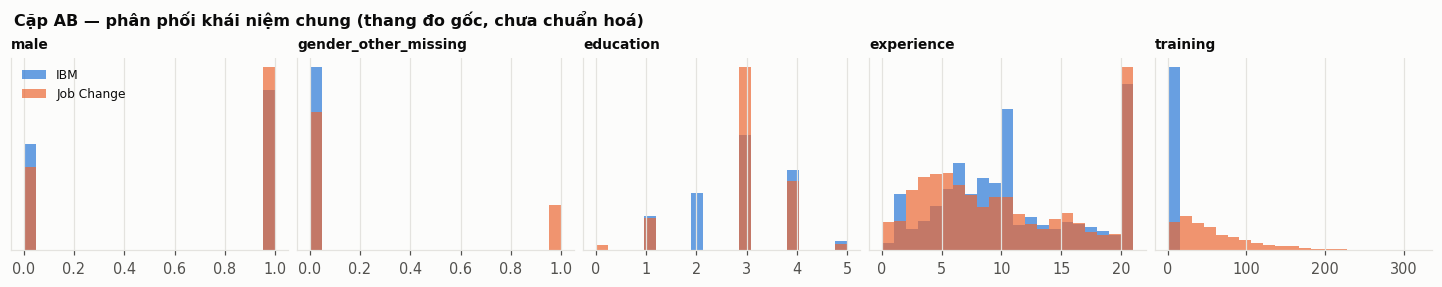

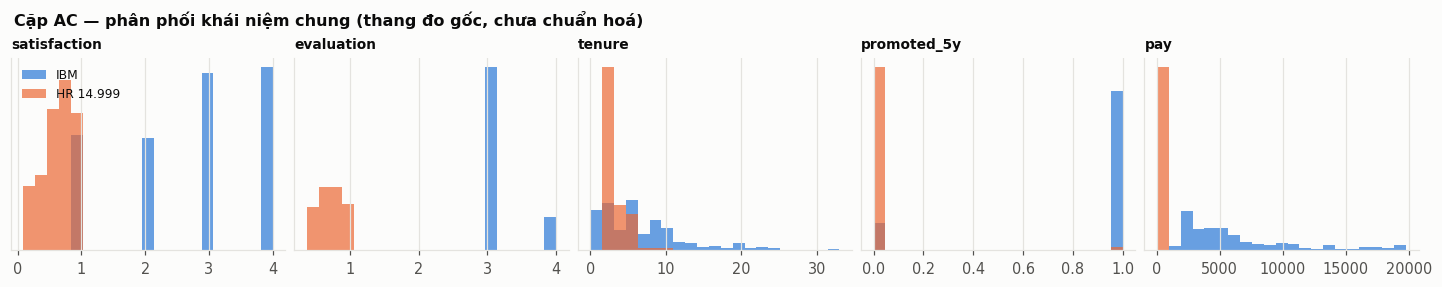

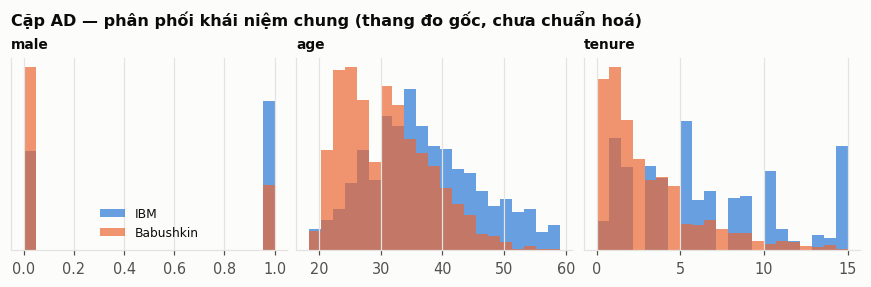

In [9]:
for p, cfg in {k: v for k, v in PAIRS.items() if set(v["domains"]) <= set(CO)}.items():
    d1, d2 = cfg["domains"]
    K1 = concepts(p, d1, D[d1][0], cfg["main"])
    K2 = concepts(p, d2, D[d2][0], cfg["main"])
    cols = list(K1.columns)
    fig, axes = plt.subplots(1, len(cols), figsize=(2.6 * len(cols), 2.5), constrained_layout=True)
    axes = np.atleast_1d(axes)
    for ax, c in zip(axes, cols):
        a, b = K1[c].dropna().astype(float), K2[c].dropna().astype(float)
        lo = min(np.nanpercentile(a, .5), np.nanpercentile(b, .5))
        hi = max(np.nanpercentile(a, 99.5), np.nanpercentile(b, 99.5))
        bins = np.linspace(lo, hi, 22) if hi > lo else 10
        ax.hist(a, bins=bins, color=C1, alpha=.70, density=True, label=SHORT[d1])
        ax.hist(b, bins=bins, color=C2, alpha=.70, density=True, label=SHORT[d2])
        ax.set_title(c, loc="left", fontsize=9, fontweight="bold", color=INK)
        ax.set_yticks([])
    axes[0].legend(frameon=False, fontsize=8)
    fig.suptitle(f"Cặp {p} — phân phối khái niệm chung (thang đo gốc, chưa chuẩn hoá)",
                 fontsize=10.5, fontweight="bold", color=INK, x=0.005, ha="left")
    plt.savefig(os.path.join(OUT, f"h3_khai_niem_{p}.png"), bbox_inches="tight", facecolor=SURFACE)
    plt.show()

## 6. Chiều tác động của khái niệm chung với nhãn

Đây là phần quan trọng nhất của notebook. Mục 6.3 của đánh giá yêu cầu **kiểm tra cùng chiều tác động trước khi chạy**, và *"khái niệm ngược chiều bị loại hoặc ghi rõ"*.

Hai thước đo, đều tính **chỉ trên phần huấn luyện** của lần chia `rep = 0`:

- **Spearman ρ** — tương quan thứ hạng giữa khái niệm và nhãn; đúng thước đo mục 6.3 yêu cầu.
- **AUC một đặc trưng** — dùng riêng khái niệm đó để dự đoán nhãn. Dưới 0,5 nghĩa là ngược chiều.

Một khái niệm **ngược chiều** khi dấu của ρ ở hai miền trái nhau — lúc đó mô hình học từ miền nguồn sẽ dự đoán sai hướng trên miền đích.

In [10]:
TRAIN = {}                                    # phần train của rep = 0, theo đúng splits.py
for d in CO:
    y = D[d][1]
    TRAIN[d] = np.array(make_splits(y, ks=(10,), R=1, test_size=0.2)[0]["train"])
    print(f"Miền {d}: {len(TRAIN[d]):,}/{len(y):,} dòng dùng cho phần phân tích có nhãn")

Miền A: 1,176/1,470 dòng dùng cho phần phân tích có nhãn
Miền B: 15,267/19,084 dòng dùng cho phần phân tích có nhãn
Miền C: 9,592/11,991 dòng dùng cho phần phân tích có nhãn
Miền D: 762/953 dòng dùng cho phần phân tích có nhãn


In [11]:
def chieu_tac_dong(p, dom, cset):
    X, y, _ = D[dom]
    tr = TRAIN[dom]
    K = concepts(p, dom, X, cset).iloc[tr]
    yy = y[tr]
    out = []
    for c in K.columns:
        v = K[c].astype(float)
        ok = v.notna().to_numpy()
        if ok.sum() < 30 or v[ok].nunique() < 2:
            out.append({"khai_niem": c, "spearman": np.nan, "p_value": np.nan, "auc_don": np.nan})
            continue
        rho, pv = stats.spearmanr(v[ok], yy[ok])
        out.append({"khai_niem": c, "spearman": rho, "p_value": pv,
                    "auc_don": roc_auc_score(yy[ok], v[ok])})
    return pd.DataFrame(out).set_index("khai_niem")


CHIEU = {}
for p, cfg in {k: v for k, v in PAIRS.items() if set(v["domains"]) <= set(CO)}.items():
    d1, d2 = cfg["domains"]
    t1 = chieu_tac_dong(p, d1, cfg["main"]).add_prefix(f"{d1}_")
    t2 = chieu_tac_dong(p, d2, cfg["main"]).add_prefix(f"{d2}_")
    t = pd.concat([t1, t2], axis=1)
    s1, s2 = np.sign(t[f"{d1}_spearman"]), np.sign(t[f"{d2}_spearman"])
    chua_xd = t[[f"{d1}_spearman", f"{d2}_spearman"]].isna().any(axis=1)
    t["cung_chieu"] = np.where(chua_xd, np.nan, (s1 == s2).astype(float))
    CHIEU[p] = t
    print(f"\n{'='*78}\nCặp {p}: {SHORT[d1]} ↔ {SHORT[d2]}  (ngữ nghĩa nhãn {cfg['label_semantics']})")
    display(t[[f"{d1}_spearman", f"{d1}_auc_don", f"{d2}_spearman", f"{d2}_auc_don", "cung_chieu"]].round(3))
    nguoc   = t.index[t["cung_chieu"] == 0].tolist()
    chua    = t.index[t["cung_chieu"].isna()].tolist()
    print("⚠️  NGƯỢC CHIỀU      :", nguoc if nguoc else "không có")
    if chua:
        print("ℹ️  Không xác định  :", chua, "— hằng số ở một miền nên không tính được ρ")

pd.concat({p: t for p, t in CHIEU.items()}, names=["cap"]).to_csv(
    os.path.join(ROOT, "eda", "bang3_chieu_tac_dong.csv"), encoding="utf-8-sig")


Cặp AB: IBM ↔ Job Change  (ngữ nghĩa nhãn khác (hành vi ↔ ý định))


,A_spearman,A_auc_don,B_spearman,B_auc_don,cung_chieu
khai_niem,,,,,
male,0.011,0.507,-0.069,0.463,0.0
gender_other_missing,NaN,NaN,0.071,0.536,NaN
education,-0.028,0.479,-0.016,0.491,1.0
experience,-0.197,0.346,-0.184,0.378,1.0
training,-0.058,0.457,-0.015,0.490,1.0


⚠️  NGƯỢC CHIỀU      : ['male']
ℹ️  Không xác định  : ['gender_other_missing'] — hằng số ở một miền nên không tính được ρ

Cặp AC: IBM ↔ HR 14.999  (ngữ nghĩa nhãn giống (hành vi ↔ hành vi))


,A_spearman,A_auc_don,C_spearman,C_auc_don,cung_chieu
khai_niem,,,,,
satisfaction,-0.112,0.415,-0.321,0.251,1.0
evaluation,-0.009,0.496,-0.003,0.497,1.0
tenure,-0.185,0.355,0.259,0.690,0.0
promoted_5y,-0.008,0.496,-0.043,0.493,1.0
pay,-0.194,0.348,-0.112,0.422,1.0


⚠️  NGƯỢC CHIỀU      : ['tenure']



Cặp AD: IBM ↔ Babushkin  (ngữ nghĩa nhãn giống (hành vi ↔ hành vi))


,A_spearman,A_auc_don,D_spearman,D_auc_don,cung_chieu
khai_niem,,,,,
male,0.011,0.507,-0.021,0.491,0.0
age,-0.166,0.370,-0.069,0.460,1.0
tenure,-0.187,0.354,-0.030,0.483,1.0


⚠️  NGƯỢC CHIỀU      : ['male']


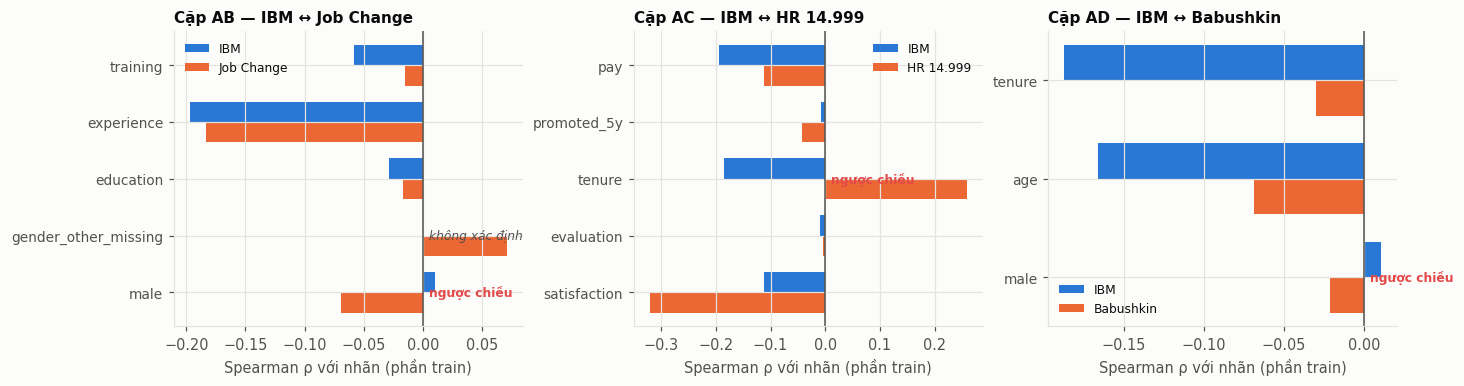

In [12]:
# Hình tổng hợp: Spearman của từng khái niệm ở hai miền trong cặp
CAP = {k: v for k, v in PAIRS.items() if set(v["domains"]) <= set(CO)}
fig, axes = plt.subplots(1, max(1, len(CAP)), figsize=(4.4 * max(1, len(CAP)), 3.4), constrained_layout=True)
axes = np.atleast_1d(axes)

for ax, (p, cfg) in zip(axes, CAP.items()):
    d1, d2 = cfg["domains"]
    t = CHIEU[p]
    yy = np.arange(len(t))
    h = .36
    ax.barh(yy + h/2, t[f"{d1}_spearman"], height=h, color=C1, label=SHORT[d1])
    ax.barh(yy - h/2, t[f"{d2}_spearman"], height=h, color=C2, label=SHORT[d2])
    ax.axvline(0, color=INK2, lw=1)
    ax.set_yticks(yy); ax.set_yticklabels(t.index, fontsize=9)
    ax.set_xlabel("Spearman ρ với nhãn (phần train)")
    ax.set_title(f"Cặp {p} — {SHORT[d1]} ↔ {SHORT[d2]}", loc="left",
                 fontsize=10, fontweight="bold", color=INK)
    ax.legend(frameon=False, fontsize=8)
    for i, ok in enumerate(t["cung_chieu"].to_numpy()):
        if ok == 0:
            ax.annotate("ngược chiều", (0, i), xytext=(4, 0), textcoords="offset points",
                        fontsize=8, color="#e34948", va="center", fontweight="bold")
        elif np.isnan(ok):
            ax.annotate("không xác định", (0, i), xytext=(4, 0), textcoords="offset points",
                        fontsize=8, color="#52514e", va="center", style="italic")

plt.savefig(os.path.join(OUT, "h4_chieu_tac_dong.png"), bbox_inches="tight", facecolor=SURFACE)
plt.show()

### Nhận xét mục 6

**Kết quả quan trọng nhất: xác nhận được khái niệm `tenure` ngược chiều ở cặp AC.**

| Khái niệm | IBM (A) | HR 14.999 (C) | Kết luận |
|---|---|---|---|
| `tenure` | ρ = **−0,185** · AUC **0,355** | ρ = **+0,259** · AUC **0,690** | **Ngược chiều** |

Con số này khớp đúng ghi chú trong `pairs.py` (*"bỏ thâm niên vì chiều tác động ngược nhau giữa A (AUC 0,35) và C (0,69)"*), và cả hai đều có ý nghĩa thống kê rất mạnh (p ≈ 1e−10 và 2e−146). Ở IBM, thâm niên càng cao thì càng **ít** nghỉ việc; ở HR 14.999 thì ngược lại. Việc tập `consistent` loại khái niệm này là có căn cứ.

**Các khái niệm cùng chiều và đáng tin:**

- `experience` ở cặp AB: ρ = −0,197 (A) và −0,184 (B), cả hai đều rất có ý nghĩa. Đây là khái niệm chung mạnh nhất của cặp AB.
- `satisfaction` ở cặp AC: ρ = −0,112 (A) và −0,321 (C), cùng chiều, nhưng **mạnh hơn hẳn ở C**. Phù hợp với việc `satisfaction_level` của miền C là biến liên tục 0–1, còn `JobSatisfaction` của IBM chỉ có 4 bậc.
- `pay` ở cặp AC: ρ = −0,194 (A) và −0,112 (C), cùng chiều.

**Các khái niệm gần như không mang thông tin:**

- `evaluation` ở cặp AC: ρ = −0,009 (A, p = 0,76) và −0,003 (C, p = 0,74). **Cả hai đều không có ý nghĩa thống kê.** Khái niệm này cùng chiều về mặt hình thức nhưng thực chất vô dụng.
- `promoted_5y`, `education`, `training`: ρ đều dưới 0,06 về trị tuyệt đối.

**Hai trường hợp đặc biệt ở cặp AB:**

- `male`: ρ = +0,011 ở A nhưng **p = 0,72**, tức không khác 0 một cách có ý nghĩa. Dấu ngược với B (ρ = −0,069) nên bị đánh dấu ngược chiều, nhưng thực chất chỉ là nhiễu. **Không nên kết luận giới tính ngược chiều.**
- `gender_other_missing`: miền A **không có** hạng mục "khác/thiếu" cho giới tính nên cột này là hằng số 0, không tính được ρ. Notebook đánh dấu *không xác định* chứ không phải *ngược chiều*.

**Cặp AD (IBM ↔ Babushkin):** `age` và `tenure` cùng chiều (ρ âm ở cả hai miền: lớn tuổi hơn, thâm niên cao hơn thì ít nghỉ hơn), nhưng **tín hiệu ở miền D yếu hơn hẳn miền A**: ở A, ρ = −0,166 (`age`) và −0,187 (`tenure`); ở D, ρ = −0,069 (p = 0,057) và −0,030 (p = 0,41), AUC 0,460 và 0,483. Không khái niệm nào của D có ý nghĩa ở mức 0,05 trên phần train. `male` bị đánh dấu ngược chiều nhưng p = 0,72 (A) và 0,56 (D) — cũng chỉ là nhiễu, giống cặp AB.

## 6b. Khái niệm chung của K2 (L0, L1) sau căn chỉnh C1

Kịch bản K2 lấy **A (IBM) làm đích**, nguồn là B hoặc C, với hai mức lược đồ theo `prereg/k2_khai_niem.json`:

- **L0**: tập khái niệm chính của cặp (B: `canon4`, C: `core`).
- **L1**: tập mở rộng (B: `canon5`, C: `ext`) — gồm các khái niệm có ở ít nhất 2 trong 4 bộ dữ liệu.

**C1** là bước căn chỉnh theo miền: mỗi khái niệm liên tục được điền khuyết bằng trung vị rồi đưa qua `QuantileTransformer(output_distribution="normal")`, **fit riêng cho từng miền và không dùng nhãn** (lớp `Enc("rank")` trong `kb1_pair.py`). Khái niệm nhị phân giữ nguyên. Làm giống `k2_run.py`: phía nguồn fit trên toàn bộ miền nguồn; phía đích A fit trên phần train của `rep = 0`.

Câu hỏi của mục này: **sau C1, phân phối biên của từng khái niệm ở hai miền có khớp nhau không?** Đo bằng thống kê Kolmogorov–Smirnov (KS, 0 = trùng khớp, 1 = tách rời hoàn toàn) trước và sau C1.

In [13]:
from kb1_pair import Enc

KN = json.load(open(os.path.join(ROOT, "prereg", "k2_khai_niem.json"), encoding="utf-8"))
PAIR_OF = {"B": "AB", "C": "AC"}
L1_SET  = {"B": "canon5", "C": "ext"}              # như k2_run.py


def can_chinh_c1(pair, dom, cset, fit_idx=None):
    # Trả về (khái niệm thang gốc, khái niệm sau C1); C1 fit trên fit_idx (None = toàn bộ miền)
    binary = PAIRS[pair]["binary"]
    K = concepts(pair, dom, D[dom][0], cset)
    enc = Enc("rank", binary)
    enc.fit_source(K if fit_idx is None else K.iloc[fit_idx])
    ten = [c for c in K.columns if c not in binary] + [c for c in K.columns if c in binary]   # thứ tự cột của ColumnTransformer
    Z = pd.DataFrame(enc.src.transform(K), columns=ten, index=K.index)[list(K.columns)]
    return K, Z


C1_TAB, C1_Z = [], {}
for s in [s for s in "BC" if s in CO and "A" in CO]:
    p = PAIR_OF[s]
    for lv, cset in [("L0", PAIRS[p]["main"]), ("L1", L1_SET[s])]:
        Ka, Za = can_chinh_c1(p, "A", cset, fit_idx=TRAIN["A"])
        Ks, Zs = can_chinh_c1(p, s, cset)
        assert sorted(Ka.columns) == sorted(KN["nguon"][s][lv]["khai_niem_chung"]), (s, lv, list(Ka.columns))
        C1_Z[(s, lv)] = (Za, Zs)
        for c in Ka.columns:
            a0, s0 = Ka[c].dropna().astype(float), Ks[c].dropna().astype(float)
            C1_TAB.append({
                "nguon": s, "muc": lv, "khai_niem": c,
                "nhi_phan": c in PAIRS[p]["binary"],
                "so_gia_tri_A": a0.nunique(), "so_gia_tri_nguon": s0.nunique(),
                "KS_truoc_C1": stats.ks_2samp(a0, s0).statistic,
                "KS_sau_C1": stats.ks_2samp(Za[c], Zs[c]).statistic,
                "TB_A_sau": Za[c].mean(), "DLC_A_sau": Za[c].std(),
                "TB_nguon_sau": Zs[c].mean(), "DLC_nguon_sau": Zs[c].std(),
            })

C1T = pd.DataFrame(C1_TAB).set_index(["nguon", "muc", "khai_niem"])
display(C1T.round(3))
C1T.to_csv(os.path.join(ROOT, "eda", "bang5_khai_niem_sau_C1.csv"), encoding="utf-8-sig")

nhi_phan  so_gia_tri_A  so_gia_tri_nguon  KS_truoc_C1  KS_sau_C1  TB_A_sau  DLC_A_sau  TB_nguon_sau  DLC_nguon_sau
nguon muc khai_niem                                                                                                                               
B     L0  male                      True             2                 2        0.089      0.089     0.600      0.490         0.689          0.463
          gender_other_missing      True             1                 2        0.246      0.246     0.000      0.000         0.246          0.431
          education                False             5                 5        0.183      0.443    -0.320      2.067         0.032          1.243
          experience               False            22                22        0.120      0.080     0.485      2.079         0.550          2.339
          training                 False             7               241        0.957      0.186     0.043      1.649         0.001          1.003
      L1  male                      True             2                 2        0.089      0.089     0.600      0.490         0.689          0.463
          gender_other_missing      True             1                 2        0.246      0.246     0.000      0.000         0.246          0.431
          education                False             5                 5        0.183      0.443    -0.320      2.067         0.032          1.243
          experience               False            22                22        0.120      0.080     0.485      2.079         0.550          2.339
          training                 False             7               241        0.957      0.186     0.043      1.649         0.001          1.003
          tenure                   False             6                 6        0.390      0.376     2.675      3.218         0.904          2.435
C     L0  satisfaction             False             4                92        0.992      0.304     0.540      3.678        -0.006          1.156
          evaluation               False             2                65        1.000      0.845    -3.601      3.752         0.047          1.167
          tenure                   False            37                 8        0.448      0.285    -0.101      1.270        -0.927          2.521
          promoted_5y               True             2                 2        0.837      0.837     0.854      0.353         0.017          0.129
          pay                      False          1349                 3        1.000      0.478    -0.003      1.010        -1.831          3.455
      L1  satisfaction             False             4                92        0.992      0.304     0.540      3.678        -0.006          1.156
          evaluation               False             2                65        1.000      0.845    -3.601      3.752         0.047          1.167
          tenure                   False            37                 8        0.448      0.285    -0.101      1.270        -0.927          2.521
          promoted_5y               True             2                 2        0.837      0.837     0.854      0.353         0.017          0.129
          pay                      False          1349                 3        1.000      0.478    -0.003      1.010        -1.831          3.455
          overtime                  True             2                 2        0.213      0.213     0.283      0.451         0.496          0.500
          dept_sales                True             2                 2        0.033      0.033     0.303      0.460         0.270          0.444
          dept_hr                   True             2                 2        0.007      0.007     0.043      0.203         0.050          0.218

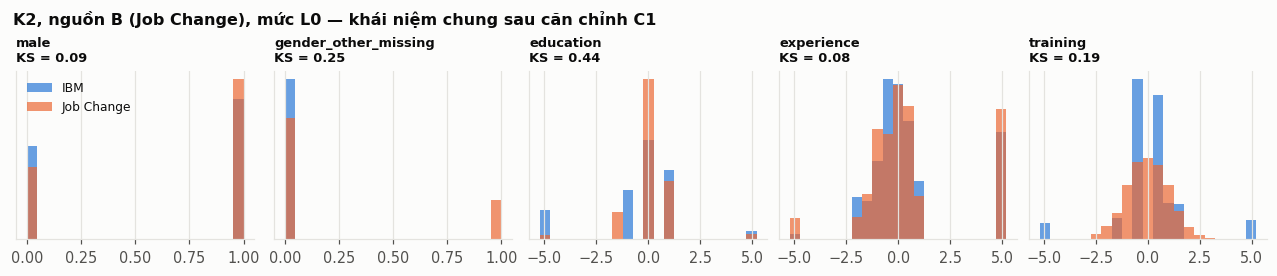

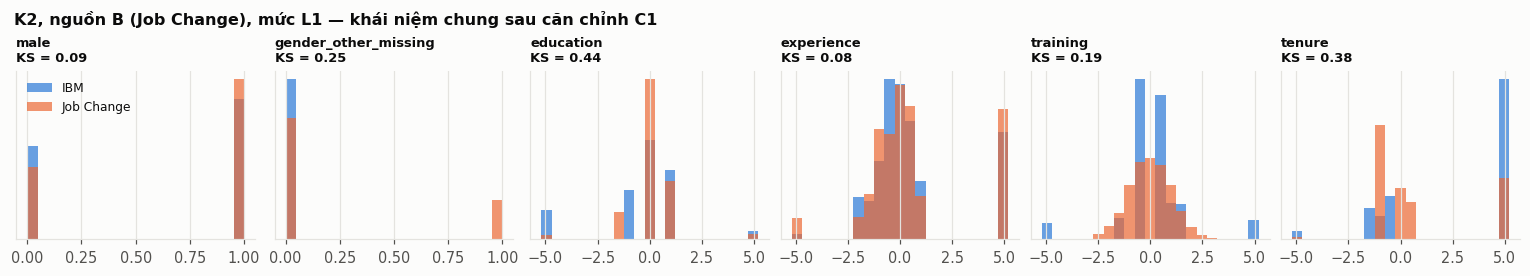

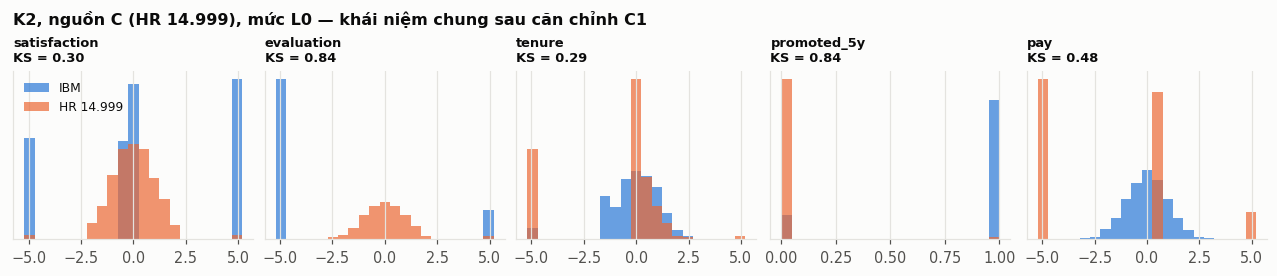

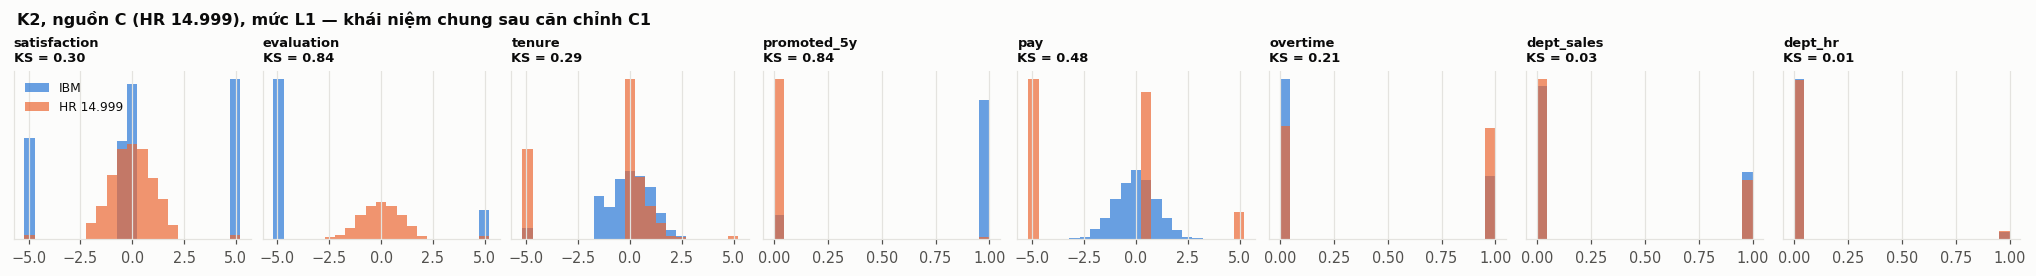

In [14]:
for (s, lv), (Za, Zs) in C1_Z.items():
    cols = list(Za.columns)
    fig, axes = plt.subplots(1, len(cols), figsize=(2.3 * len(cols), 2.4), constrained_layout=True)
    axes = np.atleast_1d(axes)
    for ax, c in zip(axes, cols):
        a, b = Za[c].astype(float), Zs[c].astype(float)
        lo, hi = min(a.min(), b.min()), max(a.max(), b.max())
        bins = np.linspace(lo, hi, 22) if hi > lo else 10
        ax.hist(a, bins=bins, color=C1, alpha=.70, density=True, label=SHORT["A"])
        ax.hist(b, bins=bins, color=C2, alpha=.70, density=True, label=SHORT[s])
        ks = C1T.loc[(s, lv, c), "KS_sau_C1"]
        ax.set_title(f"{c}\nKS = {ks:.2f}", loc="left", fontsize=8.5, fontweight="bold", color=INK)
        ax.set_yticks([])
    axes[0].legend(frameon=False, fontsize=8)
    fig.suptitle(f"K2, nguồn {s} ({SHORT[s]}), mức {lv} — khái niệm chung sau căn chỉnh C1",
                 fontsize=10.5, fontweight="bold", color=INK, x=0.005, ha="left")
    plt.savefig(os.path.join(OUT, f"h5_c1_{s}_{lv}.png"), bbox_inches="tight", facecolor=SURFACE)
    plt.show()

### Nhận xét mục 6b

**L0 và L1.** Với nguồn B, L1 = L0 thêm `tenure`. Với nguồn C, L1 = L0 thêm ba khái niệm nhị phân `overtime`, `dept_sales`, `dept_hr`.

**C1 căn chỉnh tốt khi khái niệm liên tục, nhiều giá trị ở cả hai miền:** `training` (A 7 giá trị, B 241) KS từ 0,957 xuống 0,186; `satisfaction` cặp AC (A 4 bậc, C 92 giá trị) từ 0,992 xuống 0,304; `tenure` cặp AC từ 0,448 xuống 0,285; `experience` từ 0,120 xuống 0,080.

**C1 không căn chỉnh được khái niệm ít bậc.** `QuantileTransformer` đưa giá trị nhỏ nhất của mỗi miền về −5,199 và lớn nhất về +5,199. Khi một khái niệm chỉ có vài bậc, cả nhóm người ở bậc thấp nhất hoặc cao nhất bị dồn về hai cực này:

- `evaluation` ở A chỉ có 2 giá trị (3 và 4) nên sau C1 thành −5,2 và +5,2, trong khi ở C có 65 giá trị, phân phối gần chuẩn quanh 0. KS sau C1 vẫn **0,845**.
- `satisfaction` ở A: bậc 1 thành −5,2, bậc 4 thành +5,2; `pay` ở C (3 bậc lương) tương tự. Độ lệch chuẩn sau C1 của các khái niệm này từ 2 đến 3,8 thay vì khoảng 1.
- `education` (5 bậc ở cả A và B): KS **tăng** từ 0,183 lên 0,443 sau C1.

**Khái niệm nhị phân giữ nguyên qua C1**, nên chênh lệch tỷ lệ giữa hai miền giữ nguyên: `promoted_5y` là 1 ở 85% nhân viên A nhưng chỉ 2% ở C (KS 0,837).

Đây là quan sát EDA, không thay đổi thiết kế đã chốt của K2. Ghi lại để nhóm cân nhắc khi diễn giải H-C1 và ablation −C1: với khái niệm ít bậc, C1 không đưa hai miền về cùng phân phối và tạo ra giá trị ±5,2 ở đầu vào của mô hình nguồn.

## 6c. Đối chiếu AUC đơn biến với Bảng A5.5a–b

Bảng A5.5a (cặp AC) và A5.5b (cặp AD) của báo cáo ghi AUC một đặc trưng của từng khái niệm, sinh bởi `bao_cao/make_pairs_json.py` và lưu ở `bao_cao/pairs.json`. Cách tính trong bảng: tập khái niệm `ext`, **toàn bộ dữ liệu** của mỗi miền (không chia train/test).

Ô dưới tính lại theo đúng cách đó và so với số trong `pairs.json`, kèm AUC chỉ trên phần train `rep = 0` (cách của mục 6) để xem kết luận về chiều tác động có đổi không.

In [15]:
def auc_don(y, v):
    v = pd.Series(v).astype(float)
    ok = v.notna().to_numpy()
    return roc_auc_score(np.asarray(y)[ok], v[ok]) if v[ok].nunique() > 1 else np.nan


A55 = json.load(open(os.path.join(ROOT, "bao_cao", "pairs.json"), encoding="utf-8"))
so = lambda t: float(t.replace(",", "."))

doi_chieu = []
for p in [p for p in ["AC", "AD"] if set(PAIRS[p]["domains"]) <= set(CO)]:
    d1, d2 = PAIRS[p]["domains"]
    K1, K2 = concepts(p, d1, D[d1][0], "ext"), concepts(p, d2, D[d2][0], "ext")
    core = set(concepts(p, d1, D[d1][0], PAIRS[p]["main"]).columns)
    bang = A55[f"map_{p}"]
    assert len(bang) == K1.shape[1], (p, len(bang), list(K1.columns))
    for c, dong in zip(K1.columns, bang):            # make_pairs_json.py ghi dòng theo đúng thứ tự cột
        y1, y2 = D[d1][1], D[d2][1]
        r = {"cap": p, "khai_niem": c, "tap": "core" if c in core else "ext",
             f"A55_{d1}": so(dong[3]), f"A55_{d2}": so(dong[4]),
             f"tinh_lai_{d1}": auc_don(y1, K1[c]), f"tinh_lai_{d2}": auc_don(y2, K2[c]),
             f"train_{d1}": auc_don(y1[TRAIN[d1]], K1[c].iloc[TRAIN[d1]]),
             f"train_{d2}": auc_don(y2[TRAIN[d2]], K2[c].iloc[TRAIN[d2]]),
             "ket_luan_A55": dong[5].replace("*", "")}
        r["lech_lon_nhat"] = max(abs(r[f"tinh_lai_{d1}"] - r[f"A55_{d1}"]), abs(r[f"tinh_lai_{d2}"] - r[f"A55_{d2}"]))
        r["cung_chieu_train"] = (r[f"train_{d1}"] - .5) * (r[f"train_{d2}"] - .5) > 0
        doi_chieu.append(r)

for p in sorted({r["cap"] for r in doi_chieu}):
    d1, d2 = PAIRS[p]["domains"]
    t = pd.DataFrame([r for r in doi_chieu if r["cap"] == p]).set_index("khai_niem")
    print(f"\n{'='*78}\nCặp {p}: {SHORT[d1]} ↔ {SHORT[d2]} — Bảng A5.5{'a' if p == 'AC' else 'b'}")
    display(t[["tap", f"A55_{d1}", f"tinh_lai_{d1}", f"train_{d1}", f"A55_{d2}", f"tinh_lai_{d2}", f"train_{d2}",
               "lech_lon_nhat", "ket_luan_A55", "cung_chieu_train"]].round(3))

DC = pd.DataFrame(doi_chieu)
DC.to_csv(os.path.join(ROOT, "eda", "bang6_doi_chieu_A55.csv"), index=False, encoding="utf-8-sig")
print(f"\nLệch lớn nhất giữa số tính lại và Bảng A5.5 (làm tròn 3 chữ số): {DC['lech_lon_nhat'].max():.4f}")


Cặp AC: IBM ↔ HR 14.999 — Bảng A5.5a


,tap,A55_A,tinh_lai_A,train_A,A55_C,tinh_lai_C,train_C,lech_lon_nhat,ket_luan_A55,cung_chieu_train
khai_niem,,,,,,,,,,
satisfaction,core,0.422,0.422,0.415,0.253,0.253,0.251,0.0,Cùng chiều,True
evaluation,core,0.501,0.501,0.496,0.504,0.504,0.497,0.0,Gần như không có tín hiệu ở một miền,True
tenure,core,0.351,0.351,0.355,0.691,0.691,0.690,0.0,Ngược chiều,False
promoted_5y,core,0.499,0.499,0.496,0.492,0.492,0.493,0.0,Gần như không có tín hiệu ở một miền,True
pay,core,0.344,0.344,0.348,0.421,0.421,0.422,0.0,Cùng chiều,True
overtime,ext,0.651,0.651,0.663,0.528,0.528,0.525,0.0,Cùng chiều,True
dept_sales,ext,0.551,0.551,0.561,0.504,0.504,0.502,0.0,Gần như không có tín hiệu ở một miền,True
dept_hr,ext,0.505,0.505,0.507,0.504,0.504,0.502,0.0,Gần như không có tín hiệu ở một miền,True



Cặp AD: IBM ↔ Babushkin — Bảng A5.5b


,tap,A55_A,tinh_lai_A,train_A,A55_D,tinh_lai_D,train_D,lech_lon_nhat,ket_luan_A55,cung_chieu_train
khai_niem,,,,,,,,,,
male,core,0.520,0.520,0.507,0.485,0.485,0.491,0.0,Gần như không có tín hiệu ở một miền,False
age,core,0.366,0.366,0.370,0.465,0.465,0.460,0.0,Cùng chiều,True
tenure,core,0.350,0.350,0.354,0.473,0.473,0.483,0.0,Cùng chiều,True
prof_hr,ext,0.505,0.505,0.507,0.457,0.457,0.452,0.0,Gần như không có tín hiệu ở một miền,False
prof_sales,ext,0.551,0.551,0.561,0.507,0.507,0.512,0.0,Gần như không có tín hiệu ở một miền,True



Lệch lớn nhất giữa số tính lại và Bảng A5.5 (làm tròn 3 chữ số): 0.0005


### Nhận xét mục 6c

- Tính lại theo đúng cách của `make_pairs_json.py` cho **cùng giá trị** với Bảng A5.5a–b ở cả 13 khái niệm của hai cặp (lệch lớn nhất 0,000 sau khi làm tròn 3 chữ số), kể cả miền D vừa bổ sung dữ liệu.
- Khi chỉ dùng phần train `rep = 0`, AUC lệch tối đa 0,013 và **không đổi kết luận chiều tác động** ở khái niệm nào.
- Hai khái niệm có dấu trái nhau ở cặp AD (`male`, `prof_hr`) trái nhau cả khi tính trên toàn bộ dữ liệu, và Bảng A5.5b đã xếp vào nhóm *gần như không có tín hiệu ở một miền*.

## 7. So sánh bốn miền — tổng kết

In [16]:
tk = B1[["Bộ dữ liệu", "Dòng còn lại", "Số cột", "Tỷ lệ dương"]].copy()
MOTA = {"A": ("Hư cấu", "Đã nghỉ việc"), "B": ("Thật (ứng viên)", "Ý định đổi việc"),
        "C": ("Mô phỏng", "Đã nghỉ việc"), "D": ("Thật", "Đã nghỉ việc (kiểm duyệt)")}
tk["Loại dữ liệu"] = [MOTA[d][0] for d in CO]
tk["Ngữ nghĩa nhãn"] = [MOTA[d][1] for d in CO]
tk["Cột có giá trị thiếu"] = [int((MI.mien == d).sum()) for d in CO]
display(tk)
tk.to_csv(os.path.join(ROOT, "eda", "bang4_so_sanh_bon_mien.csv"), encoding="utf-8-sig")

,Bộ dữ liệu,Dòng còn lại,Số cột,Tỷ lệ dương,Loại dữ liệu,Ngữ nghĩa nhãn,Cột có giá trị thiếu
Miền,,,,,,,
A,IBM,1470,30,0.1612,Hư cấu,Đã nghỉ việc,0
B,Job Change,19084,11,0.2492,Thật (ứng viên),Ý định đổi việc,8
C,HR 14.999,11991,9,0.1660,Mô phỏng,Đã nghỉ việc,0
D,Babushkin,953,15,0.5100,Thật,Đã nghỉ việc (kiểm duyệt),0


## 8. Nhận xét chung

**a) Ngữ nghĩa nhãn.** A và C đều là *đã nghỉ việc*; B là *ý định đổi việc*. Đây là biến độc lập chính của RQ4: cặp AC cùng ngữ nghĩa, cặp AB khác ngữ nghĩa. (Miền D cũng là *đã nghỉ việc* nhưng có kiểm duyệt — xem mục b.)

**b) Kiểm duyệt ở miền D.** Nhãn `event = 0` của Babushkin nghĩa là *chưa nghỉ tính đến thời điểm thu thập*, không phải *chắc chắn ở lại*. Nhãn âm của D vì vậy **không cùng ý nghĩa** với nhãn âm của A và C, dù cả ba đều được gọi là "đã nghỉ việc".

**c) Mất cân bằng.** Tỷ lệ dương: A **16,12%**, B **24,92%**, C **16,60%**, D **51,00%**. PR-AUC của bộ đoán ngẫu nhiên **bằng đúng tỷ lệ dương**, nên không so trực tiếp PR-AUC giữa các miền được — phải so với mốc riêng của từng miền. Miền D đặc biệt khác biệt: với tỷ lệ 51%, một mô hình vô dụng cũng đạt PR-AUC ≈ 0,51.

**d) Quy mô và số cột.** B có 19.084 dòng nhưng chỉ 11 cột; A chỉ 1.470 dòng nhưng 30 cột; C ở giữa với 11.991 dòng và 9 cột. Chênh lệch này ảnh hưởng trực tiếp tới việc chọn k trong đường cong học: với A, k = 500 đã chiếm hơn 40% tập huấn luyện, trong khi với B thì chỉ khoảng 3%.

**e) Số khái niệm chung.** AB có 5 (gồm cả cờ giới tính khác/thiếu), AC có 5 ở tập `core`, AD chỉ có 3 (`male`, `age`, `tenure`). Đây là **biến gây nhiễu khi so sánh các cặp**: cặp ít khái niệm chung bị thiệt về mặt thông tin, không hẳn do ngữ nghĩa nhãn khác nhau. Khi kết luận về RQ4 cần tách bạch hai yếu tố này.

**f) Chiều tác động.** Tìm được **một khái niệm ngược chiều thật sự**: `tenure` ở cặp AC (AUC 0,355 so với 0,690). Trường hợp `male` ở cặp AB bị đánh dấu ngược chiều nhưng ρ ở miền A không có ý nghĩa thống kê (p = 0,72) nên không kết luận được. `gender_other_missing` không xác định được vì miền A không có hạng mục đó. Ở cặp AD, `age` và `tenure` cùng chiều nhưng tín hiệu ở D yếu và không có ý nghĩa thống kê.

**g) Chất lượng dữ liệu.** Miền C mất **20,1%** số dòng do trùng hoàn toàn — dấu hiệu dữ liệu mô phỏng. Miền B có **25 nhóm nhãn mâu thuẫn**: cùng hồ sơ nhưng nhãn khác nhau, nghĩa là bản thân nhãn có nhiễu không thể khử. Miền A sạch, không trùng dòng nào.

**h) Giá trị thiếu.** Chỉ miền B có giá trị thiếu, ở **8/11 cột**. A và C không thiếu ô nào. Điều này ảnh hưởng tới bước điền khuyết: với cặp AB, bộ điền khuyết gần như chỉ làm việc trên dữ liệu của miền B.

---

## Tệp xuất ra

| Tệp | Nội dung |
|---|---|
| `eda/bang1_tong_quan_mien.csv` | Số dòng, loại trùng, tỷ lệ dương |
| `eda/bang2_ty_le_thieu.csv` | Tỷ lệ thiếu theo cột |
| `eda/bang3_chieu_tac_dong.csv` | Spearman và AUC một đặc trưng của khái niệm chung |
| `eda/bang4_so_sanh_bon_mien.csv` | Bảng so sánh tổng kết |
| `eda/bang5_khai_niem_sau_C1.csv` | Khái niệm L0, L1 của K2: KS trước và sau C1, trung bình và độ lệch chuẩn sau C1 |
| `eda/bang6_doi_chieu_A55.csv` | AUC đơn biến tính lại, đối chiếu Bảng A5.5a–b |
| `eda/hinh/h1…h5_*.png` | Năm nhóm hình |

## Ghi chú về tái lập

- Dữ liệu đọc qua `pairs.LOADERS`, nên số dòng sau loại trùng **trùng khớp** với mọi thí nghiệm trong `results/`.
- Phần train lấy từ `splits.make_splits(y, R=1, test_size=0.2)` với `rep = 0` — cùng hàm mà `kb1_v2.py` và `g0_23.py` dùng.
- Kiểm tra SHA-256 của bốn tệp dữ liệu bằng `python kiem_tra_tai_lap.py` trước khi chạy.